More optimized notebook. This is to plot the yearly DO distribution for SUMMER ONLY.

In [1]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.interpolate import griddata
import imageio.v2 as imageio # Use v2 to avoid deprecation warning [cite: 396]
import os
import glob

# --- Configuration ---
base_data_path = '../data/raw/environmental_data'
manual_filepath = '../sources/水環境総合情報サイト/water_manual.xls'
output_dir = '../reports/figures/seasonal_gif_frames'
os.makedirs(output_dir, exist_ok=True)

# --- Load Shapefiles ---
gdfs = []
for dirpath, _, filenames in os.walk(base_data_path):
    if 'output.shp' in filenames:
        try:
            year = int(os.path.basename(dirpath).split('_')[0])
            gdf = gpd.read_file(os.path.join(dirpath, 'output.shp'))
            gdf['year'] = year
            gdfs.append(gdf)
        except (ValueError, IndexError):
            continue

all_points_gdf = pd.concat(gdfs, ignore_index=True)
all_points_gdf['watercode'] = all_points_gdf['watercode'].astype(int)

# --- Load Manual & Merge ---
codes_df = pd.read_excel(manual_filepath, sheet_name='3. Water mass code', header=3)
codes_df = codes_df.rename(columns={'Water Mass Code': 'watercode', 'Water Mass Name': 'watermass_name'})
codes_df['watercode'] = codes_df['watercode'].astype(int)
merged_gdf = all_points_gdf.merge(codes_df, on='watercode', how='left')

# --- Define Season & Filter for Summer Only ---
def get_season(month):
    if month in [6, 7, 8]: return 'Summer'
    elif month in [9, 10, 11]: return 'Autumn'
    elif month in [12, 1, 2]: return 'Winter'
    else: return 'Spring'

merged_gdf['season'] = merged_gdf['surveymont'].apply(get_season)
merged_gdf['do_'] = pd.to_numeric(merged_gdf['do_'], errors='coerce')

# Filter: Bottom Layer (saisuipoin==2), Summer, and valid DO [cite: 80-82]
analysis_df = merged_gdf[
    (merged_gdf['saisuipoin'] == 2) & 
    (merged_gdf['season'] == 'Summer')
].dropna(subset=['do_']).copy()

# Determine global min/max for consistent colorbar animation [cite: 84-86]
vmin, vmax = analysis_df['do_'].min(), analysis_df['do_'].max()
print(f"Data prepared: {len(analysis_df)} points. DO Range: {vmin:.2f} - {vmax:.2f}")

Data prepared: 5238 points. DO Range: 0.10 - 12.00


In [15]:
def create_summer_map(year, data, vmin, vmax, output_dir):
    """Generates and saves a single Summer DO heatmap for a given year."""
    year_data = data[data['year'] == year]
    
    # Skip if insufficient data points for interpolation
    if len(year_data) < 4:
        return

    # --- Interpolation ---
    # Define grid limits (Seto Inland Sea area) [cite: 108, 126]
    extent = [130.6, 135.6, 32.75, 35.1]
    grid_x, grid_y = np.mgrid[extent[0]:extent[1]:200j, extent[2]:extent[3]:200j]
    
    points = np.array([year_data.geometry.x, year_data.geometry.y]).T
    values = year_data['do_'].values
    grid_z = griddata(points, values, (grid_x, grid_y), method='cubic')

    # --- Plotting ---
    fig = plt.figure(figsize=(12, 8))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent(extent, crs=ccrs.PlateCarree())

    # --- Add Gridlines and Labels (Restored) ---
    # draw_labels=True adds the axis labels (lat/lon)
    gl = ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False, 
                      linewidth=0.5, color='gray', alpha=0.5, linestyle='--', zorder=3)
    gl.top_labels = False  # Optional: Turn off top labels if you prefer
    gl.right_labels = False # Optional: Turn off right labels if you prefer

    # Add features
    ax.add_feature(cfeature.LAND, edgecolor='black', zorder=1)
    ax.add_feature(cfeature.OCEAN, zorder=0)
    ax.add_feature(cfeature.COASTLINE, zorder=2)

    # Plot Heatmap
    contour = ax.contourf(
        grid_x, grid_y, grid_z,
        levels=np.linspace(vmin, vmax, 15),
        cmap='jet_r',
        transform=ccrs.PlateCarree(),
        zorder=0
    )

    # Aesthetics
    cbar = fig.colorbar(contour, ax=ax, fraction=0.03, pad=0.04)
    cbar.set_label('Interpolated Dissolved Oxygen (mg/L)')
    ax.set_title(f'Summer Bottom DO Distribution ({year})', fontsize=16)

    # Save
    output_path = os.path.join(output_dir, f'frame_{year}.png')
    plt.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Saved frame for {year}")

Saved frame for 2022


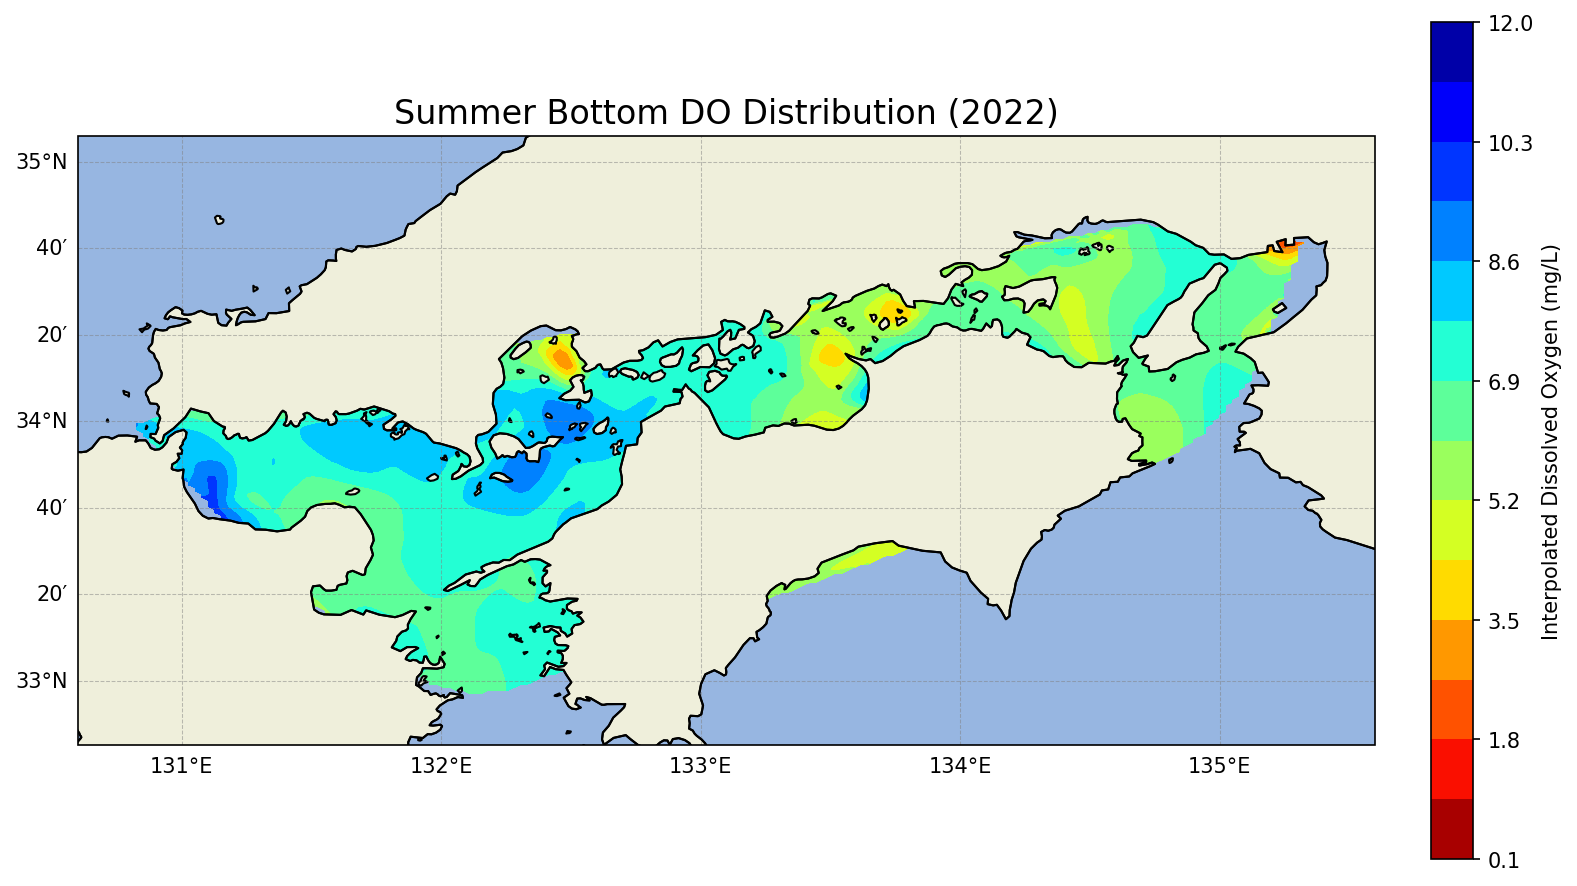

In [16]:
# --- Test Single Frame (Year 2022) ---
from IPython.display import Image

# 1. Define the test year
test_year = 2022

# 2. Generate the map for the test year
create_summer_map(test_year, analysis_df, vmin, vmax, output_dir)

# 3. Display the saved image inline to verify gridlines and labels
test_image_path = os.path.join(output_dir, f'frame_{test_year}.png')
display(Image(filename=test_image_path))

In [17]:
# --- Generate Frames ---
years = sorted(analysis_df['year'].unique())
for year in years:
    create_summer_map(year, analysis_df, vmin, vmax, output_dir)

# --- Create GIF ---
print("\nStitching frames into GIF...")
images = []
file_list = sorted(glob.glob(os.path.join(output_dir, '*.png')))

for filename in file_list:
    images.append(imageio.imread(filename))

gif_path = '../reports/figures/animations/summer_do_animation.gif'
imageio.mimsave(gif_path, images, fps=1) # Adjusted fps for smoother viewing
print(f"Animation saved to {gif_path}")

Saved frame for 1981
Saved frame for 1982
Saved frame for 1983
Saved frame for 1984
Saved frame for 1985
Saved frame for 1986
Saved frame for 1987
Saved frame for 1988
Saved frame for 1989
Saved frame for 1990
Saved frame for 1991
Saved frame for 1992
Saved frame for 1993
Saved frame for 1994
Saved frame for 1995
Saved frame for 1996
Saved frame for 1997
Saved frame for 1998
Saved frame for 1999
Saved frame for 2000
Saved frame for 2001
Saved frame for 2002
Saved frame for 2003
Saved frame for 2004
Saved frame for 2005
Saved frame for 2006
Saved frame for 2007
Saved frame for 2008
Saved frame for 2009
Saved frame for 2010
Saved frame for 2011
Saved frame for 2012
Saved frame for 2013
Saved frame for 2014
Saved frame for 2015
Saved frame for 2016
Saved frame for 2017
Saved frame for 2018
Saved frame for 2019
Saved frame for 2020
Saved frame for 2021
Saved frame for 2022

Stitching frames into GIF...
Animation saved to ../reports/figures/animations/summer_do_animation.gif
